# Day 6: Logistic Regression, KNN, Decision Trees, Random Forests
System 7 Internship | Week 2 | Aayla Zahid Butt

## Notes
- **Logistic regression:** a linear score is passed through a sigmoid to give a probability between 0 and 1. If it is above 0.5 the class is 1. Used for classification, in spite of its name.
- **K-Nearest Neighbors (KNN):** a new point gets the majority class of its k nearest training points. It uses distance, so features must be scaled.
- **Decision tree:** asks yes/no questions about the features to split the data into groups. Easy to understand, but a deep tree can overfit.
- **Random forest:** many decision trees trained on random parts of the data. The final answer is the majority vote, which is usually more accurate and stable than one tree.

## Sigmoid function

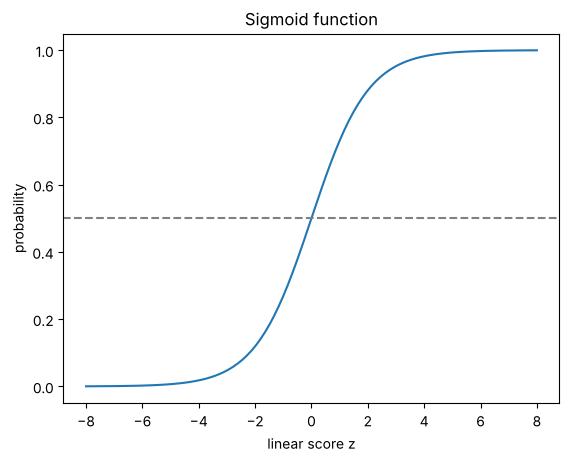

In [1]:
import numpy as np
import matplotlib.pyplot as plt

z = np.linspace(-8, 8, 200)
plt.plot(z, 1 / (1 + np.exp(-z)))
plt.axhline(0.5, color='gray', linestyle='--')
plt.xlabel('linear score z')
plt.ylabel('probability')
plt.title('Sigmoid function')
plt.show()

## Models on the Breast Cancer dataset
This is a built-in Scikit-learn dataset: 569 samples and 30 features. The target is malignant (212) or benign (357). The data is split 80/20.

In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

bc = load_breast_cancer(as_frame=True)
Xc, yc = bc.data, bc.target
print(Xc.shape, bc.target_names.tolist())

Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(
    Xc, yc, test_size=0.2, random_state=42, stratify=yc)

(569, 30) ['malignant', 'benign']


In [3]:
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
dt = DecisionTreeClassifier(max_depth=4, random_state=42)
rf = RandomForestClassifier(n_estimators=200, random_state=42)
models = {'Logistic Regression': lr, 'KNN (k=5)': knn,
          'Decision Tree (depth 4)': dt, 'Random Forest (200 trees)': rf}

for name, m in models.items():
    m.fit(Xc_tr, yc_tr)
    print(f'{name:28s} {m.score(Xc_te, yc_te):.3f}')

Logistic Regression          0.982
KNN (k=5)                    0.956
Decision Tree (depth 4)      0.939


Random Forest (200 trees)    0.956


## KNN with different values of k

k = 1 0.939
k = 3 0.982
k = 5 0.956
k = 7 0.974
k = 9 0.974
k = 11 0.974
k = 13 0.974
k = 15 0.974


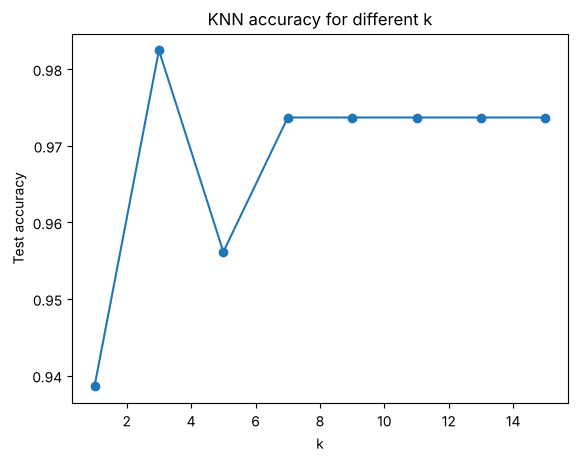

In [4]:
ks = list(range(1, 16, 2))
accs = []
for k in ks:
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    m.fit(Xc_tr, yc_tr)
    accs.append(m.score(Xc_te, yc_te))
    print('k =', k, round(accs[-1], 3))

plt.plot(ks, accs, marker='o')
plt.xlabel('k')
plt.ylabel('Test accuracy')
plt.title('KNN accuracy for different k')
plt.show()

k = 3 gave the highest accuracy and k = 1 the lowest. k = 5 is used for the comparison. Choosing k from test accuracy is not ideal; a validation set should be used for that.